# Face Detection + Age/Gender Estimation (OpenCV DNN)
This notebook runs a complete pipeline for:
- Loading pretrained face, age, and gender models
- Detecting faces and predicting age/gender per face
- Visualizing results in the notebook with Matplotlib
- Testing robustness under rotation/brightness/blur
- Processing a video and saving an annotated output with FPS overlay

## Cell 1 — Imports and project paths
Imports the required libraries (OpenCV, NumPy, Matplotlib) and defines `BASE_DIR`, `ASSETS_DIR`, and `MODELS_DIR` so all files load from a consistent location.

In [1]:
import os, time
import cv2
import numpy as np
import matplotlib.pyplot as plt


BASE_DIR = r"d:\UT\Vision\CA3\Age-Gender"
ASSETS_DIR = os.path.join(BASE_DIR, "assets")
MODELS_DIR = os.path.join(BASE_DIR, "models")

## Cell 2 — Load DNN models
Builds full paths to the face detector and the age/gender classification models, then loads them using `cv2.dnn.readNet`.
Also sets the DNN backend/target to CPU for stable execution on most machines.

In [2]:
faceModel = os.path.join(MODELS_DIR, "opencv_face_detector_uint8.pb")
faceProto = os.path.join(MODELS_DIR, "opencv_face_detector.pbtxt")

ageModel  = os.path.join(MODELS_DIR, "age_net.caffemodel")
ageProto  = os.path.join(MODELS_DIR, "age_deploy.prototxt")

genderModel = os.path.join(MODELS_DIR, "gender_net.caffemodel")
genderProto = os.path.join(MODELS_DIR, "gender_deploy.prototxt")

faceNet   = cv2.dnn.readNet(faceModel, faceProto)
ageNet    = cv2.dnn.readNet(ageModel, ageProto)
genderNet = cv2.dnn.readNet(genderModel, genderProto)

# Optional (CPU):
for net in (faceNet, ageNet, genderNet):
    net.setPreferableBackend(cv2.dnn.DNN_BACKEND_OPENCV)
    net.setPreferableTarget(cv2.dnn.DNN_TARGET_CPU)

## Cell 3 — Labels and preprocessing constants
Defines the label lists (`ageList`, `genderList`) and the mean values used to normalize face crops before age/gender inference.

In [3]:
ageList =["(0-2)", "(4-6)", "(8-12)", "(15-20)", "(25-32)", "(38-43)", "(48-53)", "(60-100)"]
genderList =["Male", "Female"]
MODEL_MEAN_VALUES =(78.4263377603, 87.7689143744, 114.895847746)

## Cell 4 — Face detection helper (`highlightFace`)
Implements a helper that:
- Creates a blob for the face detector
- Runs a forward pass
- Filters detections by confidence threshold
- Returns a copy of the frame with rectangles drawn and a list of bounding boxes

In [4]:
def highlightFace(net, frame, conf_threshold=0.7):
    frameCopy = frame.copy()
    h, w = frame.shape[:2]

    blob = cv2.dnn.blobFromImage(
        frame, scalefactor=1.04, size=(300, 300),
        mean=(104, 117, 123), swapRB=True, crop=False
    )
    net.setInput(blob)
    detections = net.forward()

    bboxes = []
    # Typical shape: [1, 1, N, 7] => [batch, class, i, (id, label, conf, x1,y1,x2,y2)]
    for i in range(detections.shape[2]):
        confidence = float(detections[0, 0, i, 2])
        if confidence > conf_threshold:
            x1 = int(detections[0, 0, i, 3] * w)
            y1 = int(detections[0, 0, i, 4] * h)
            x2 = int(detections[0, 0, i, 5] * w)
            y2 = int(detections[0, 0, i, 6] * h)

            x1, y1 = max(0, x1), max(0, y1)
            x2, y2 = min(w - 1, x2), min(h - 1, y2)

            bboxes.append([x1, y1, x2, y2])
            cv2.rectangle(frameCopy, (x1, y1), (x2, y2), (0, 255, 0), 2)

    return frameCopy, bboxes

## Cell 5 — Full pipeline (`detect_face_age_gender`)
For each detected face, this function:
- Expands the bounding box by `padding`
- Optionally blurs the face ROI (robustness experiment)
- Builds a blob for the age/gender networks
- Predicts gender and age and draws the label on the output image
Returns the annotated image and a structured list of predictions.

In [5]:
def detect_face_age_gender(frame, faceNet, ageNet, genderNet, padding=20, conf_threshold=0.7, blur_face_before_age_gender=False):
    resultImg, faceBoxes = highlightFace(faceNet, frame, conf_threshold=conf_threshold)

    if not faceBoxes:
        return resultImg, []

    h, w = frame.shape[:2]
    outputs = []

    for (x1, y1, x2, y2) in faceBoxes:
        x1p = max(0, x1 - padding)
        y1p = max(0, y1 - padding)
        x2p = min(w - 1, x2 + padding)
        y2p = min(h - 1, y2 + padding)

        face = frame[y1p:y2p, x1p:x2p].copy()
        if face.size == 0:
            continue

        if blur_face_before_age_gender:
            face = cv2.GaussianBlur(face, (41, 51), 0)

        blob = cv2.dnn.blobFromImage(
            face, scalefactor=1.0, size=(227, 227),
            mean=MODEL_MEAN_VALUES, swapRB=False, crop=False
        )

        genderNet.setInput(blob)
        genderPreds = genderNet.forward()
        gender = genderList[int(genderPreds[0].argmax())]

        ageNet.setInput(blob)
        agePreds = ageNet.forward()
        age = ageList[int(agePreds[0].argmax())]

        label = f"{gender}, {age}"
        yText = max(15, y1 - 10)
        cv2.putText(resultImg, label, (x1, yText), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,255,0), 2)

        outputs.append({"bbox": (x1, y1, x2, y2), "gender": gender, "age": age})

    return resultImg, outputs

## Cell 6 — Run the pipeline on the 4 test images
Loads the four images from the `assets` folder, runs `detect_face_age_gender`, and visualizes results using Matplotlib (BGR → RGB conversion for correct colors).

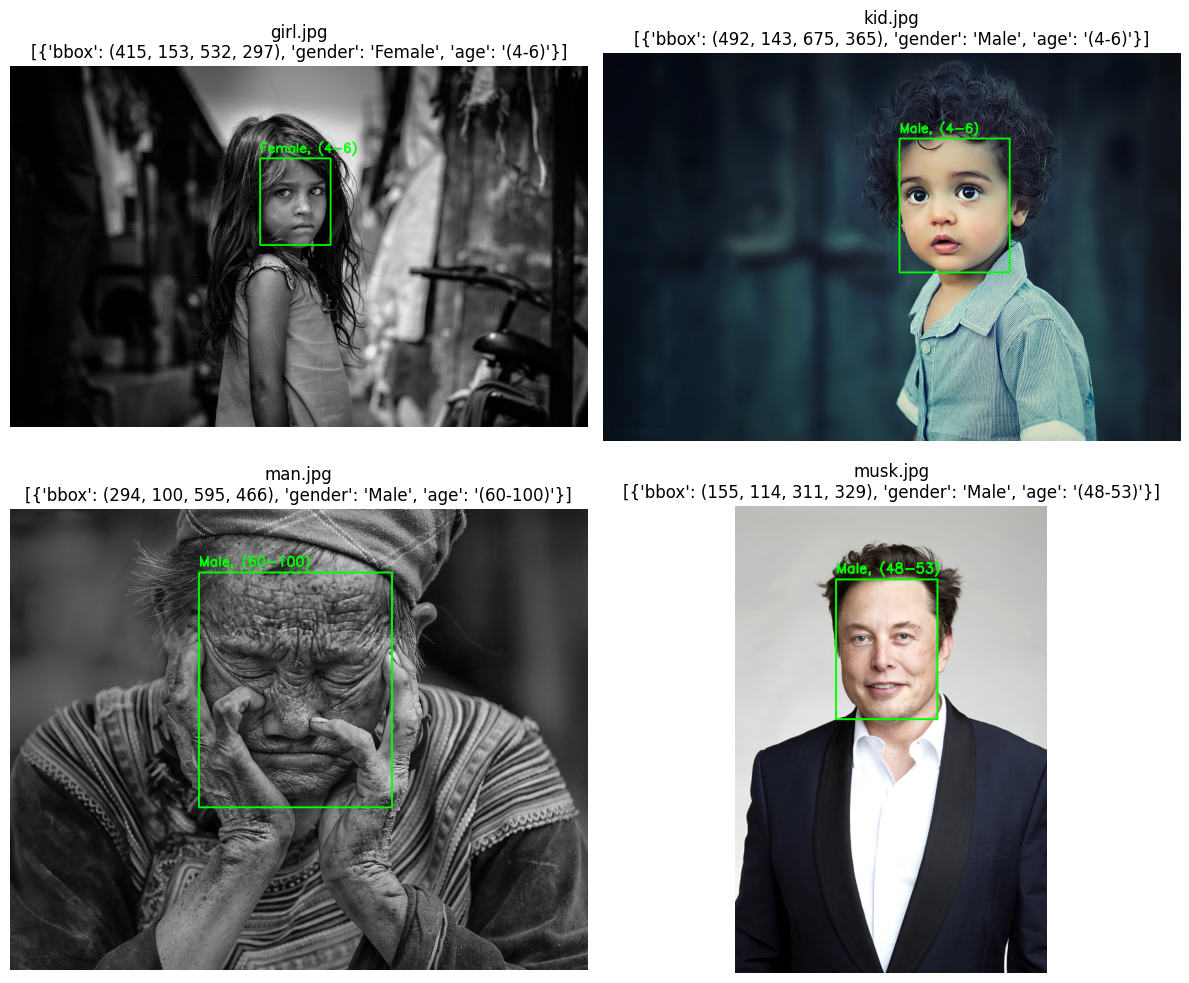

In [6]:
test_images = ["girl.jpg", "kid.jpg", "man.jpg", "musk.jpg"]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for ax, name in zip(axes, test_images):
    path = os.path.join(ASSETS_DIR, name)
    img = cv2.imread(path)
    if img is None:
        ax.set_title(f"Missing: {name}")
        ax.axis("off")
        continue

    out, info = detect_face_age_gender(img, faceNet, ageNet, genderNet)
    ax.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{name}\n{info}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Cell 7 — Brightness adjustment helper
Defines a simple brightness scaling function (`alpha` multiplier) and creates darker/brighter versions of an image to test how lighting changes affect predictions.

In [8]:
def change_brightness_bgr(img, alpha):
    tmp = np.clip(img.astype(np.float32) * alpha, 0, 255).astype(np.uint8)
    return tmp

img_dark  = change_brightness_bgr(img, 0.5)
img_bright= change_brightness_bgr(img, 1.8)

out_dark, info_dark = detect_face_age_gender(img_dark, faceNet, ageNet, genderNet)
out_bright, info_bright = detect_face_age_gender(img_bright, faceNet, ageNet, genderNet)

## Cell 8 — Robustness experiments (rotation, brightness, blur)
For each of the 4 images, this cell generates variants:
- Original
- 90° rotation
- Darker (`alpha = 0.5`)
- Brighter (`alpha = 1.8`)
- Blurred face ROI (Gaussian blur 41×51 before age/gender)
Then displays all annotated outputs side-by-side for easy comparison.

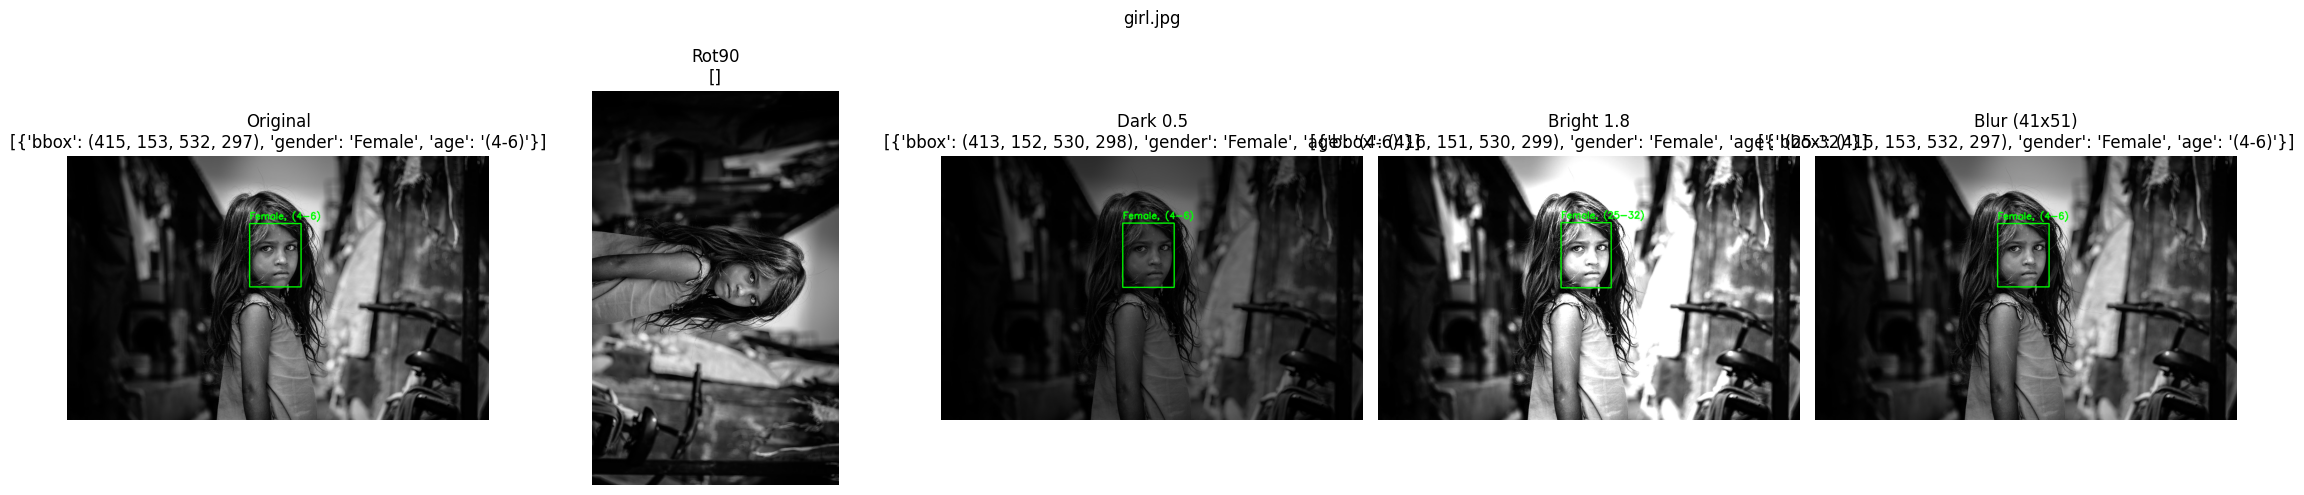

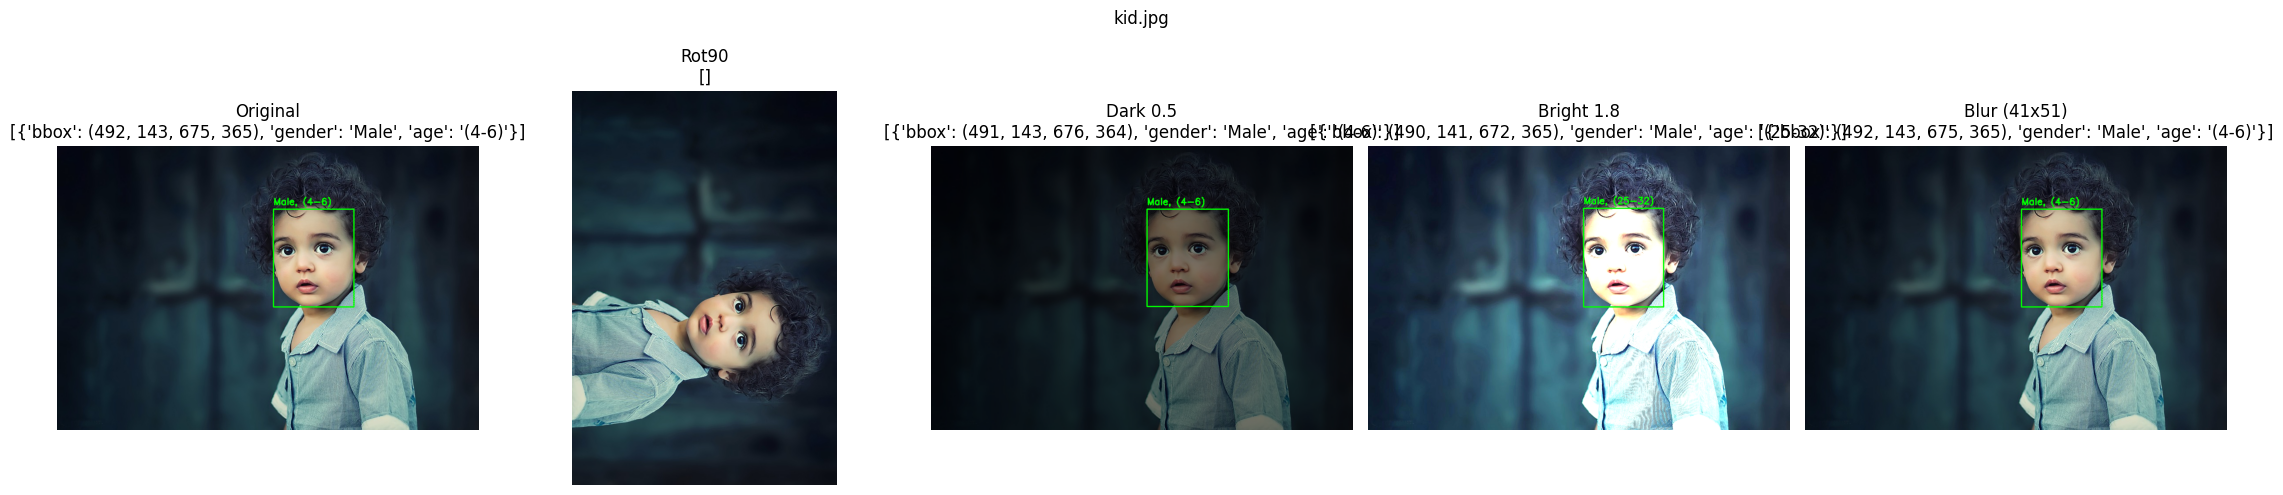

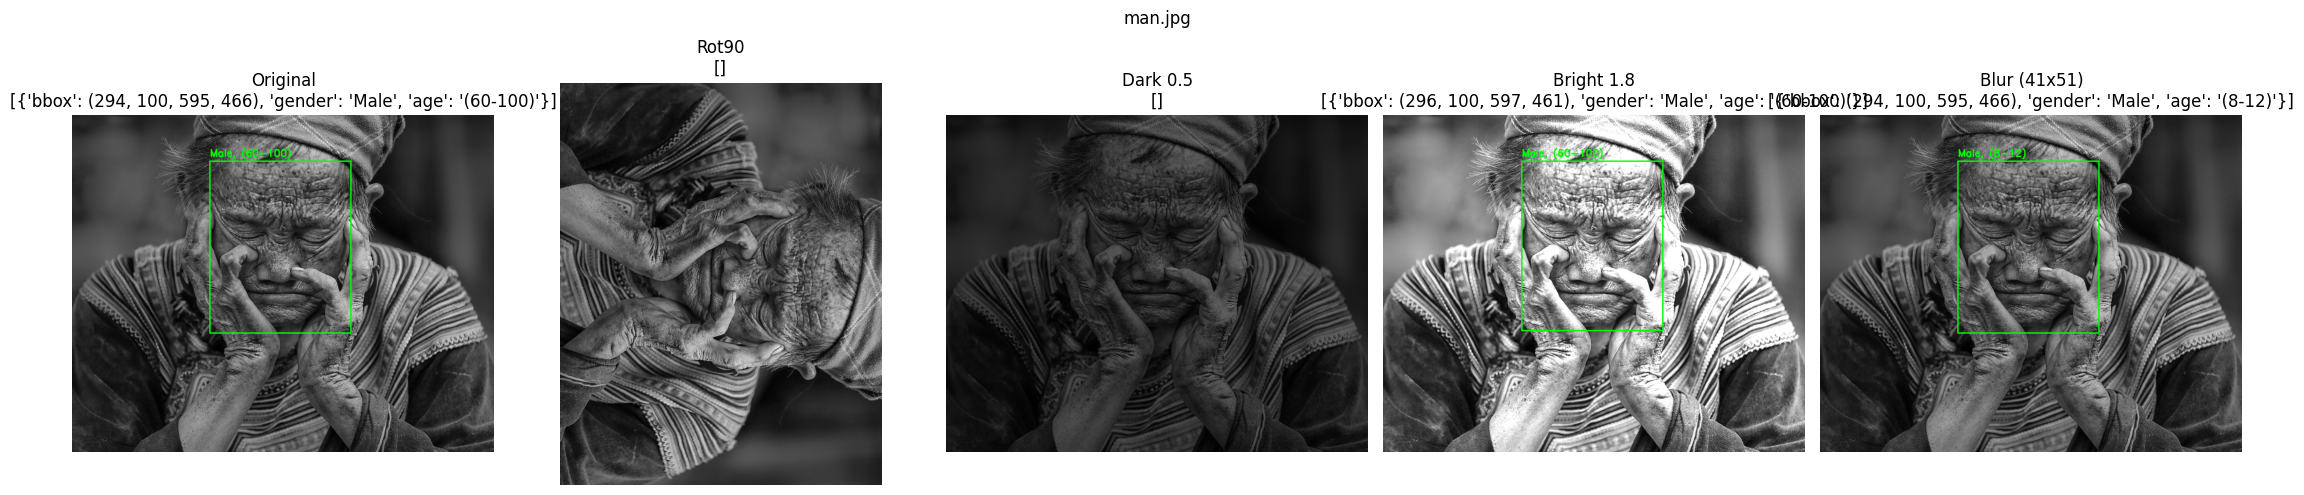

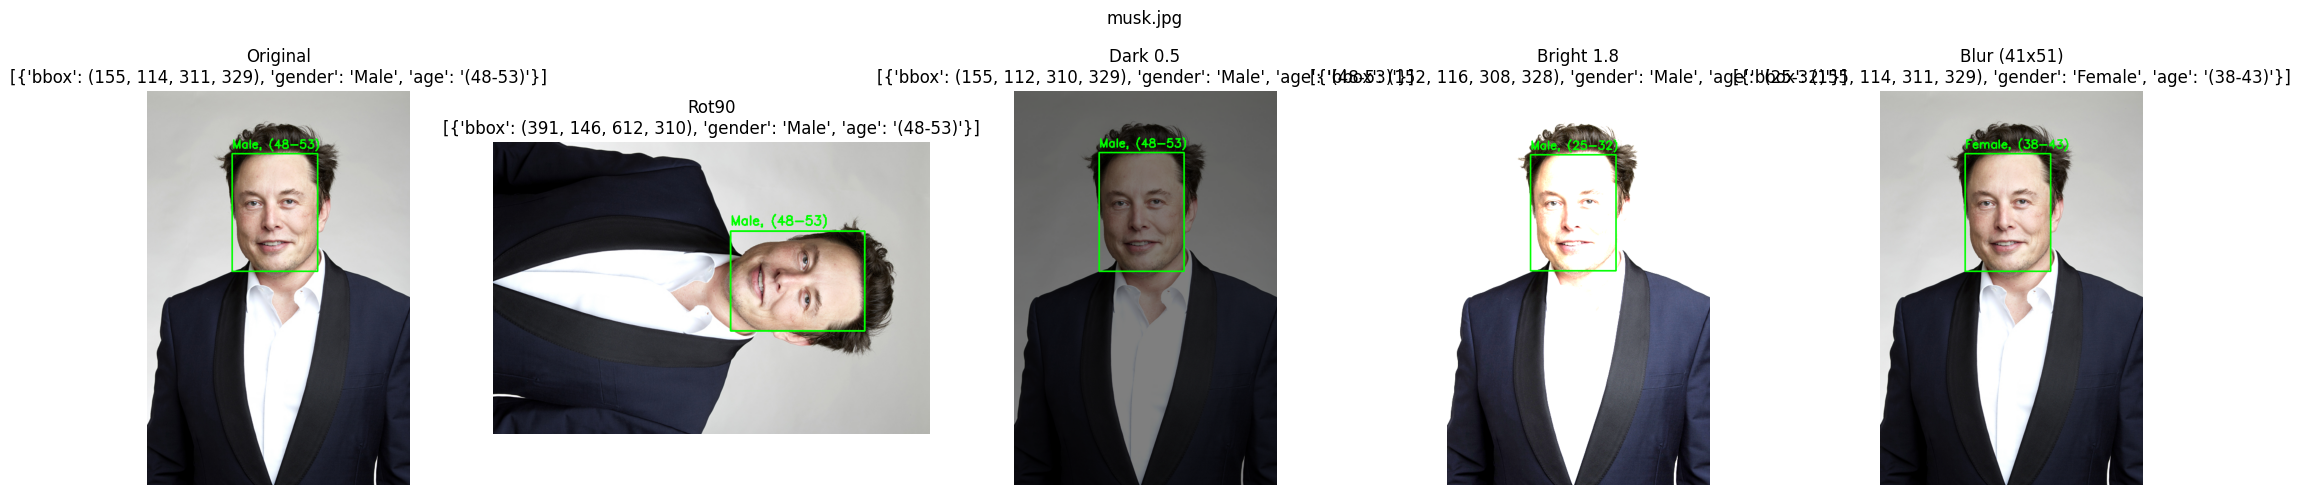

In [9]:
test_images = ["girl.jpg", "kid.jpg", "man.jpg", "musk.jpg"]

for name in test_images:
    path = os.path.join(ASSETS_DIR, name)
    img = cv2.imread(path)
    if img is None:
        print("Could not read:", path)
        continue

    variants = [
        ("Original", img),
        ("Rot90", cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)),
        ("Dark 0.5", change_brightness_bgr(img, 0.5)),
        ("Bright 1.8", change_brightness_bgr(img, 1.8)),
    ]

    fig, axes = plt.subplots(1, len(variants) + 1, figsize=(22, 5))

    # First 4 variants
    for ax, (title, im) in zip(axes[:len(variants)], variants):
        out, info = detect_face_age_gender(im, faceNet, ageNet, genderNet)
        ax.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{title}\n{info}")
        ax.axis("off")

    # Blur variant (spec: blur face ROI before age/gender)
    out_blur, info_blur = detect_face_age_gender(
        img, faceNet, ageNet, genderNet,
        blur_face_before_age_gender=True
    )
    axes[-1].imshow(cv2.cvtColor(out_blur, cv2.COLOR_BGR2RGB))
    axes[-1].set_title(f"Blur (41x51)\n{info_blur}")
    axes[-1].axis("off")

    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

## Cell 9 — Video processing + FPS overlay
Reads an input video frame-by-frame, runs the same detection pipeline, overlays a smoothed FPS estimate, and writes an annotated MP4 output using `cv2.VideoWriter`.
At the end, it prints the output path so you can locate the saved file.

In [10]:
def process_video(input_path, output_path):
    cap = cv2.VideoCapture(input_path)
    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video: {input_path}")

    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps_in = cap.get(cv2.CAP_PROP_FPS)
    if fps_in <= 0 or np.isnan(fps_in):
        fps_in = 25.0

    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    writer = cv2.VideoWriter(output_path, fourcc, fps_in, (w, h))

    prev_t = time.time()
    fps_smooth = 0.0
    alpha = 0.9  # smoothing factor

    while True:
        ok, frame = cap.read()
        if not ok:
            break

        t0 = time.time()
        out, _ = detect_face_age_gender(frame, faceNet, ageNet, genderNet)

        dt = max(1e-6, time.time() - t0)
        fps_inst = 1.0 / dt
        fps_smooth = fps_inst if fps_smooth == 0 else (alpha * fps_smooth + (1 - alpha) * fps_inst)

        cv2.putText(out, f"FPS: {fps_smooth:.1f}", (10, 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 0), 2)

        writer.write(out)

    cap.release()
    writer.release()

input_video = os.path.join(ASSETS_DIR, "Jobs_2 .mp4")
output_video = os.path.join(ASSETS_DIR, "Jobs_2_out.mp4")
process_video(input_video, output_video)
print("Wrote:", output_video)

Wrote: d:\UT\Vision\CA3\Age-Gender\assets\Jobs_2_out.mp4
